In [193]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.feature_selection import f_classif

# **`Exploratory Data Analysis (EDA):`**



**1.	Load the dataset using Python's pandas library.**


In [194]:
df = pd.read_csv('diabetes.csv')

In [195]:
df.shape

(768, 9)

In [196]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [197]:
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


**2.	Check for missing values.**


In [198]:
#missing values
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


In [199]:
#duplicates
df.duplicated().sum()

np.int64(0)

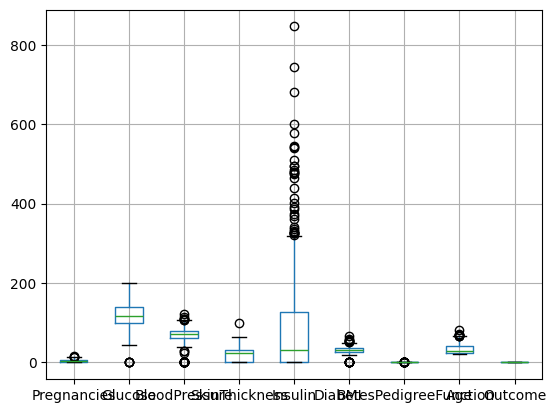

In [200]:
df.boxplot()
plt.show()

In [201]:
#outliers
def outlier_capping(df, column):
  Q1 = df[column].quantile(0.25)
  Q3 = df[column].quantile(0.75)
  IQR = Q3 - Q1
  lower_extreme = Q1 - 1.5*IQR
  upper_extreme = Q3 + 1.5*IQR
  df[column] = df[column].apply(lambda x: lower_extreme if x<lower_extreme else upper_extreme if x>upper_extreme else x)
for col in df.select_dtypes(['int', 'float']).columns:
  outlier_capping(df, col)

**3.	Explore data distributions using histograms and box plots.**


Histogram:
---

<Figure size 700x700 with 0 Axes>

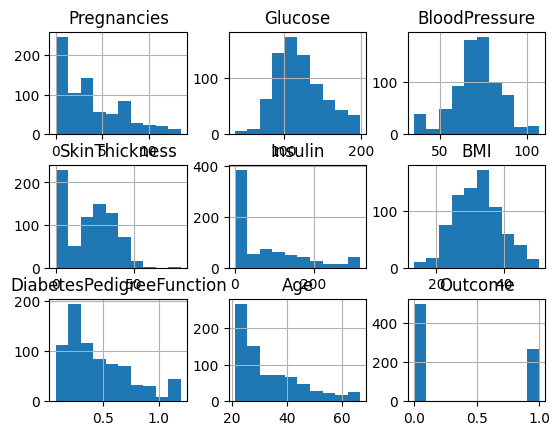

In [202]:
plt.figure(figsize=(7,7))
df.hist()
plt.show()

Box plot:
---

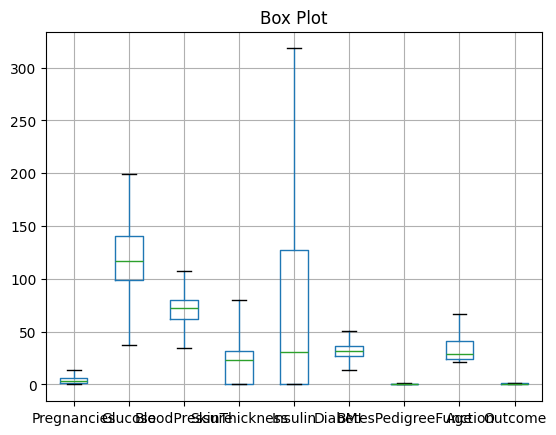

In [203]:
df.boxplot()
plt.title('Box Plot')
plt.show()

**4.	Visualize relationships between features and survival using scatter plots and bar plots.**


Scatter Plot:
---

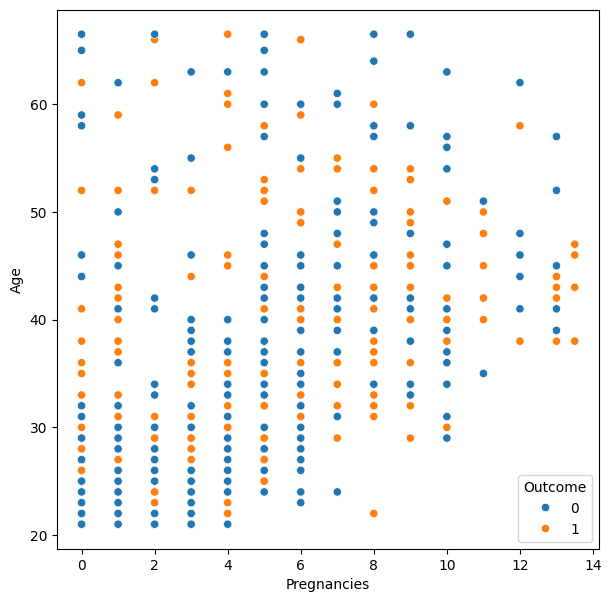

In [204]:
plt.figure(figsize=(7,7))
sns.scatterplot(data=df, x='Pregnancies', y='Age', hue='Outcome')
plt.show()

Bar Plot:
---

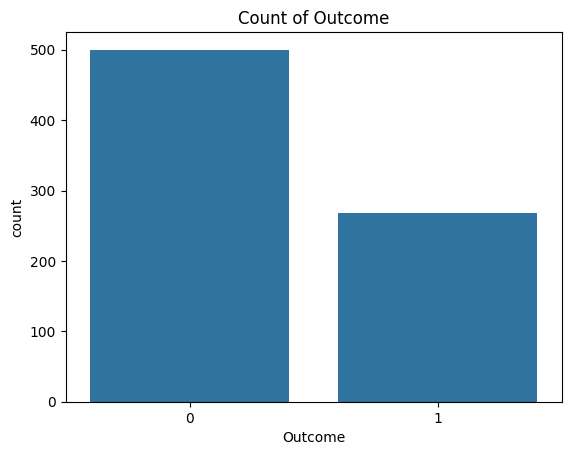

In [205]:
sns.countplot(data=df, x='Outcome')
plt.title("Count of Outcome")
plt.show()

Explanation:
---

In this EDA, I first loaded the dataset using pandas and checked the basic structure to understand the number of rows, columns and data types. Then we verified whether the dataset contains any missing values and duplicates. After that,treated outliers using outlier capping. And I analyzed the distribution of numerical columns using histograms and boxplots to observe how the values are spread and to identify outliers. Finally, we used scatter plots and count plots to understand the relationship between important features and the target variable Outcome (0 = No Diabetes, 1 = Diabetes).

# **`Data Preprocessing:`**


**1.	Impute missing values.**


In [206]:
df.isnull().sum()

,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Outcome,0


**2.	Encode categorical variables using one-hot encoding or label encoding.**


In [207]:
cat_cols = df.select_dtypes(include='object').columns
cat_cols

Index([], dtype='object')

**3.	If needed you can apply more preprocessing methods on the given dataset.**

In [208]:
target = df[['Outcome']]
features = df.drop(columns = ['Outcome'])

In [209]:
f_clas = f_classif(features,target)
f_clas

(array([ 39.1060998 , 228.27899638,   9.96114593,   4.11804863,
         12.10361486,  81.28714654,  27.13587638,  47.94475658]),
 array([6.66677148e-10, 2.46195991e-45, 1.66135754e-03, 4.27732832e-02,
        5.31674632e-04, 1.53959123e-18, 2.43985294e-07, 9.28460495e-12]))

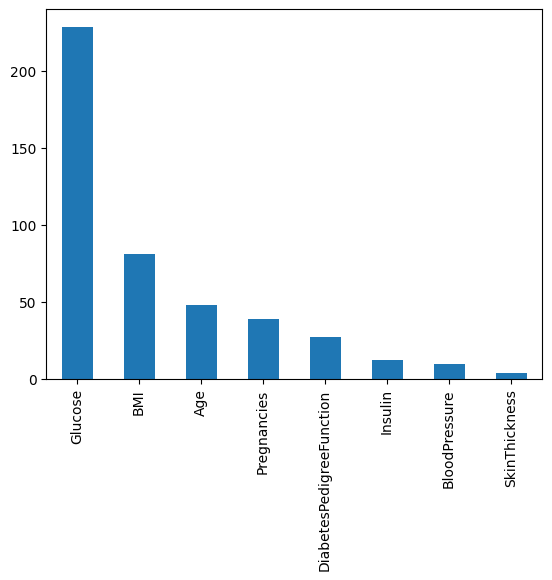

In [210]:
pd.Series(f_clas[0], index=features.columns).sort_values(ascending=False).plot(kind='bar')
plt.show()

In [211]:
features = features.drop(columns=['SkinThickness'])

In [212]:
features.head()

,Pregnancies,Glucose,BloodPressure,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6.0,148.0,72.0,0.0,33.6,0.627,50.0
1,1.0,85.0,66.0,0.0,26.6,0.351,31.0
2,8.0,183.0,64.0,0.0,23.3,0.672,32.0
3,1.0,89.0,66.0,94.0,28.1,0.167,21.0
4,0.0,137.0,40.0,168.0,43.1,1.200,33.0


Explanation:
---

In this step, I checked for missing values and found none, so no imputation was needed. Since the dataset contains only numerical features, categorical encoding was not required. I then used f-classif to identify which features contribute most to predicting the target variable. From the graph, Glucose and BMI are the most important features, while SkinThickness show very low importance and dropped to simplify the model and reduce noise for XGBM and LGBM.

# **`Building Predictive Models:`**


**1.	Split the pre processed dataset into training and testing sets.**


In [213]:
#splitting 80-20 for training and testing
x_train, x_test, y_train, y_test = train_test_split(features, target, train_size=0.8, random_state=100, stratify=target)
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(614, 7)
(154, 7)
(614, 1)
(154, 1)


**2.	Choose appropriate evaluation metrics (e.g., accuracy, precision, recall, F1-score) for model evaluation.**


In [214]:
#importing appropriate metrics for evaluation
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

**3.	Build predictive models using LightGBM and XGBoost algorithms.**


LightGBM
---

In [215]:
#installing lgbm
!pip install lightgbm

In [216]:
#importing lightgbm
import lightgbm as lgb

In [217]:
#Model buliding and also using verbose=-1 to avoid warnings
lg = lgb.LGBMClassifier( n_estimators=100, learning_rate=0.5, max_depth=3, subsample= 0.9, reg_alpha=10, reg_lambda=10, min_child_weihght=2, verbose=-1)

XGBoost
---

In [218]:
#installing xgboost
!pip install xgboost

In [219]:
#importing xgboost
import xgboost as xgb

In [220]:
#Model buliding and also using verbose=-1 to avoid warnings
xg = xgb.XGBClassifier(n_estimators=100, learning_rate=0.5, max_depth=3, subsample= 0.9, reg_alpha=10, reg_lambda=10, min_child_weihght=2, verbose=-1)

**4.	Train the models on the training set and evaluate their performance on the testing set.**



LGBM
---

In [221]:
#model training
lg.fit(x_train, y_train)

LGBMClassifier(learning_rate=0.5, max_depth=3, min_child_weihght=2,
               reg_alpha=10, reg_lambda=10, subsample=0.9, verbose=-1)

In [222]:
#prediction
y_pred = lg.predict(x_test)

In [223]:
#Model validation
acc_lg = accuracy_score(y_test, y_pred)
acc_lg

0.7792207792207793

XGBM
---


In [224]:
#Model training
xg.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.5, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
              max_leaves=None, min_child_weight=None, min_child_weihght=2,
              missing=nan, monotone_constraints=None, multi_strategy=None,
              n_estimators=100, n_jobs=None, ...)

In [225]:
#prediction
y_pred = xg.predict(x_test)

In [226]:
acc_xg = accuracy_score(y_test, y_pred)
acc_xg

0.7727272727272727

**5.	Use techniques like cross-validation and hyperparameter tuning to optimize model performance.**

**Cross-validation:**


LGBM
---

In [227]:
#using lg model for cross validation with 5 folds
cv_scores_lg = cross_val_score(lg, x_train, y_train, cv=5, scoring='accuracy')

In [228]:
print("LGBM CV Accuracy Score:", cv_scores_lg)
print("LGBM Mean CV Accuracy Score:", cv_scores_lg.mean())

LGBM CV Accuracy Score: [0.70731707 0.76422764 0.77235772 0.77235772 0.81147541]
LGBM Mean CV Accuracy Score: 0.7655471144875384


XGBoost
---

In [229]:
#using xg model for cross validation with 5 folds
cv_scores_xg = cross_val_score(xg, x_train, y_train, cv=5, scoring='accuracy')

In [230]:
print("XGBoost CV Accuracy Score:", cv_scores_xg)
print("XGBoost Mean CV Accuracy Score:", cv_scores_xg.mean())

XGBoost CV Accuracy Score: [0.72357724 0.77235772 0.77235772 0.79674797 0.79508197]
XGBoost Mean CV Accuracy Score: 0.7720245235239238


**Hyperparameter tuning:**

LGBM
---

In [231]:
#grid search to get best values for hyperparameters
param_grid_lgbm = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.1, 0.5],
    'max_depth': [3, 4, 5]
}

In [232]:
#Model buliding
grid_lgbm = GridSearchCV(lgb.LGBMClassifier(), param_grid_lgbm, cv=5)

In [233]:
#model training
grid_lgbm.fit(x_train, y_train)

GridSearchCV(cv=5, estimator=LGBMClassifier(),
             param_grid={'learning_rate': [0.01, 0.1, 0.5],
                         'max_depth': [3, 4, 5],
                         'n_estimators': [50, 100, 150]})

In [234]:
grid_lgbm.best_params_

{'learning_rate': 0.01, 'max_depth': 5, 'n_estimators': 100}

In [235]:
best_lgbm = grid_lgbm.best_estimator_

In [236]:
y_pred_lgbm = best_lgbm.predict(x_test)

In [237]:
accuracy_score(y_test, y_pred_lgbm)

0.7792207792207793

XGBoost
---

In [238]:
param_grid_xgb ={
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1],
    'max_depth': [3, 5, 7]
}

In [239]:
grid_xgb = GridSearchCV(xgb.XGBClassifier(), param_grid_xgb, cv=5)

In [240]:
grid_xgb.fit(x_train, y_train)

GridSearchCV(cv=5,
             estimator=XGBClassifier(base_score=None, booster=None,
                                     callbacks=None, colsample_bylevel=None,
                                     colsample_bynode=None,
                                     colsample_bytree=None, device=None,
                                     early_stopping_rounds=None,
                                     enable_categorical=False, eval_metric=None,
                                     feature_types=None, feature_weights=None,
                                     gamma=None, grow_policy=None,
                                     importance_type=None,
                                     interaction_constraints=None,
                                     learning_rate=None, max_bin=None,
                                     max_cat_threshold=None,
                                     max_cat_to_onehot=None,
                                     max_delta_step=None, max_depth=None,
                                     max_leaves=None, min_child_weight=None,
                                     missing=nan, monotone_constraints=None,
                                     multi_strategy=None, n_estimators=None,
                                     n_jobs=None, num_parallel_tree=None, ...),
             param_grid={'learning_rate': [0.01, 0.1], 'max_depth': [3, 5, 7],
                         'n_estimators': [50, 100, 200]})

In [241]:
grid_xgb.best_params_

{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 50}

In [242]:
y_pred_xgb = grid_xgb.predict(x_test)

In [243]:
accuracy_score(y_test, y_pred_xgb)

0.8051948051948052

Explanation:
---

The dataset was split into training and testing sets (80:20). Accuracy, precision, recall, and F1-score were chosen as evaluation metrics. LightGBM and XGBoost models were built and trained using the training data. Their performance was evaluated on the test data using accuracy. I applied 5-fold cross-validation to evaluate the consistency of both LightGBM and XGBoost across different data splits. After that, I used GridSearchCV to tune key hyperparameters like n_estimators, learning_rate, and max_depth. This optimization slightly improved the model performance.

Overall, both models performed well, but XGBoost achieved slightly higher accuracy after tuning, while LightGBM remained stable across all folds.

# **`Comparative Analysis:`**


**1.	Compare the performance metrics (e.g., accuracy, precision, recall) of LightGBM and XGBoost models.**


In [244]:
print(f'Accuracy of LightGBM: {acc_lg}')
print(f'Accuracy of XGBoost: {acc_xg}')

Accuracy of LightGBM: 0.7792207792207793
Accuracy of XGBoost: 0.7727272727272727


**2.	Visualize and interpret the results to identify the strengths and weaknesses of each algorithm.**

Visualization:

In [245]:
models = ['LightGBM', 'XGBoost']
accuracy = [acc_lg, acc_xg]

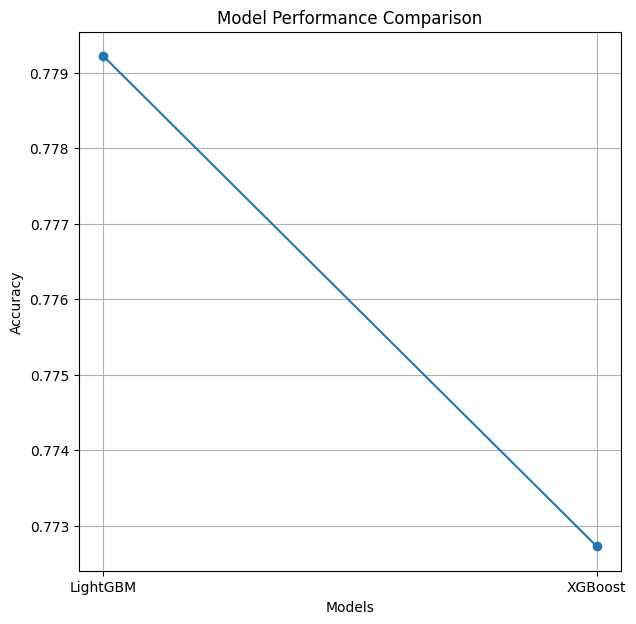

In [246]:
#using line plot to visulaise model performance based on accuracy
plt.figure(figsize=(7,7))
plt.plot(models, accuracy, marker='o')
plt.title('Model Performance Comparison')
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.grid(True)
plt.show()

Interpretion of results:

In [247]:
if acc_lg > acc_xg:
  print('LightGBM performs better than XGBoost based on accuracy.')
else:
  print('XGBoost performs better than LightGBM based on accuracy.')

LightGBM performs better than XGBoost based on accuracy.


Explanation:
---

In this step, I compared the performance of LightGBM and XGBoost using accuracy as the evaluation metric. The accuracy values of both models were printed and visualized using a line plot to make the comparison clear. From the results, LightGBM achieved slightly higher accuracy than XGBoost. Hence, LightGBM performed better on this dataset.